# PRACTICE LAB 5
## REGRESI UNTUK PREDIKSI HARGA RUMAH
### Ames Housing: Linear Regression Hingga Random Forest
**Modul 5 - EDA, Gradient Descent, robust regression, regularisasi, polynomial regression, tree, dan ensemble**

**MATA KULIAH:** Pembelajaran Mesin

---

### Fokus Praktikum
Menelusuri workflow regresi dari eksplorasi data dan Linear Regression hingga RANSAC, regularisasi, polynomial regression, Decision Tree, dan Random Forest, lalu mengevaluasi generalisasi dengan metrik yang tepat.

### Panduan Singkat Praktikum
Praktikum ini menelusuri evolusi model regresi dari implementasi linear sederhana sampai ensemble berbasis pohon. Mahasiswa diminta tidak hanya menjalankan kode, tetapi membandingkan asumsi, interpretabilitas, robustness terhadap outlier, generalisasi, dan kesiapan model untuk digunakan kembali.

| Komponen | Keterangan |
| :--- | :--- |
| **Topik utama** | Regression, Gradient Descent, RANSAC, regularization, polynomial regression, tree ensemble |
| **Dataset** | Ames Housing - subset fitur kualitas, kondisi, luas, basement, AC, dan SalePrice |
| **Pustaka** | NumPy, Pandas, Matplotlib, scikit-learn, mlxtend, Pickle |
| **Platform** | Jupyter Notebook / Google Colab / lingkungan Python yang setara |

### Capaian Pembelajaran Praktikum
* Menyiapkan subset fitur Ames Housing dan melakukan encoding variabel kategorikal serta penanganan missing value.
* Menggunakan scatterplot matrix dan heatmap korelasi untuk memahami hubungan antar fitur.
* Mengimplementasikan regresi linear dengan Gradient Descent dan menjelaskan peran learning rate serta standardisasi.
* Membandingkan solusi Gradient Descent, LinearRegression scikit-learn, dan Normal Equation.
* Menggunakan RANSAC untuk membedakan inlier dan outlier serta menganalisis pengaruh residual threshold.
* Mengevaluasi regresi menggunakan MSE, MAE, R², dan residual plot pada train-test split.
* Menjelaskan perbedaan regularisasi L1, L2, dan ElasticNet serta melengkapi eksperimen yang belum selesai pada notebook sumber.
* Membandingkan regresi linear, quadratic, dan cubic serta memahami risiko menilai kompleksitas model hanya dari training score.
* Membandingkan Decision Tree Regression dan Random Forest Regression dengan baseline regresi linear yang adil.
* Menyimpan model beserta metadata yang diperlukan agar inferensi dapat direproduksi.

---
## 1. Persiapan Lingkungan
Paket utama yang digunakan notebook

### A. Persiapan Lingkungan
Notebook menggunakan pustaka berikut. Pastikan paket tersedia pada environment Python/Jupyter yang digunakan.

Instalasi paket (jika belum tersedia):
Jika notebook dijalankan melalui local server, seluruh library yang dibutuhkan dapat dipasang sekaligus menggunakan file `requirements.txt`. Buka Terminal atau Command Prompt pada folder project, kemudian jalankan salah satu perintah berikut:
```bash
pip install -r requirements.txt
```
atau
```bash
python -m pip install -r requirements.txt
```

In [65]:
# Instalasi paket (jika belum tersedia)
# pip install pandas numpy matplotlib scikit-learn mlxtend

### B. Persiapan Library
Mengimpor library yang dibutuhkan untuk proses pengolahan dan pemodelan teks.

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.plotting import heatmap, scatterplotmatrix

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.linear_model import LinearRegression, RANSACRegressor, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

---
## 2. Persiapan Dataset Ames Housing
Notebook memilih enam kolom yang mewakili kualitas rumah, kondisi, luas, fasilitas AC sentral, luas basement, dan harga jual. Target yang diprediksi adalah `SalePrice`.

### A. Membaca Dataset

In [67]:
columns = ['Overall Qual', 'Overall Cond', 'Gr Liv Area',
           'Central Air', 'Total Bsmt SF', 'SalePrice']

df = pd.read_csv(
    'http://jse.amstat.org/v19n3/decock/AmesHousing.txt',
    sep='\t', usecols=columns
)
print(df.shape)
df.head()

(2930, 6)


,Overall Qual,Overall Cond,Total Bsmt SF,Central Air,Gr Liv Area,SalePrice
0,6,5,1080.0,Y,1656,215000
1,5,6,882.0,Y,896,105000
2,6,6,1329.0,Y,1329,172000
3,7,5,2110.0,Y,2110,244000
4,5,5,928.0,Y,1629,189900


Output Shape: `(2930, 6)`.

### B. Encoding dan missing value

In [68]:
df['Central Air'] = df['Central Air'].map({'N': 0, 'Y': 1})
print(f"Sebelum Pembersihan \n{df.isnull().sum()}")

df = df.dropna(axis=0)
print(f"\nSetelah Pembersihan \n{df.isnull().sum()}")

Sebelum Pembersihan 
Overall Qual     0
Overall Cond     0
Total Bsmt SF    1
Central Air      0
Gr Liv Area      0
SalePrice        0
dtype: int64

Setelah Pembersihan 
Overall Qual     0
Overall Cond     0
Total Bsmt SF    0
Central Air      0
Gr Liv Area      0
SalePrice        0
dtype: int64


---
## 3. Exploratory Data Analysis: Hubungan Antar Fitur
Notebook menggunakan scatterplot matrix untuk memeriksa pola pasangan variabel dan heatmap korelasi untuk melihat kekuatan hubungan linear. Narasi notebook menyoroti korelasi `SalePrice` yang relatif kuat dengan `Overall Qual` (~0.80), `Gr Liv Area` (~0.71), dan `Total Bsmt SF` (~0.63).

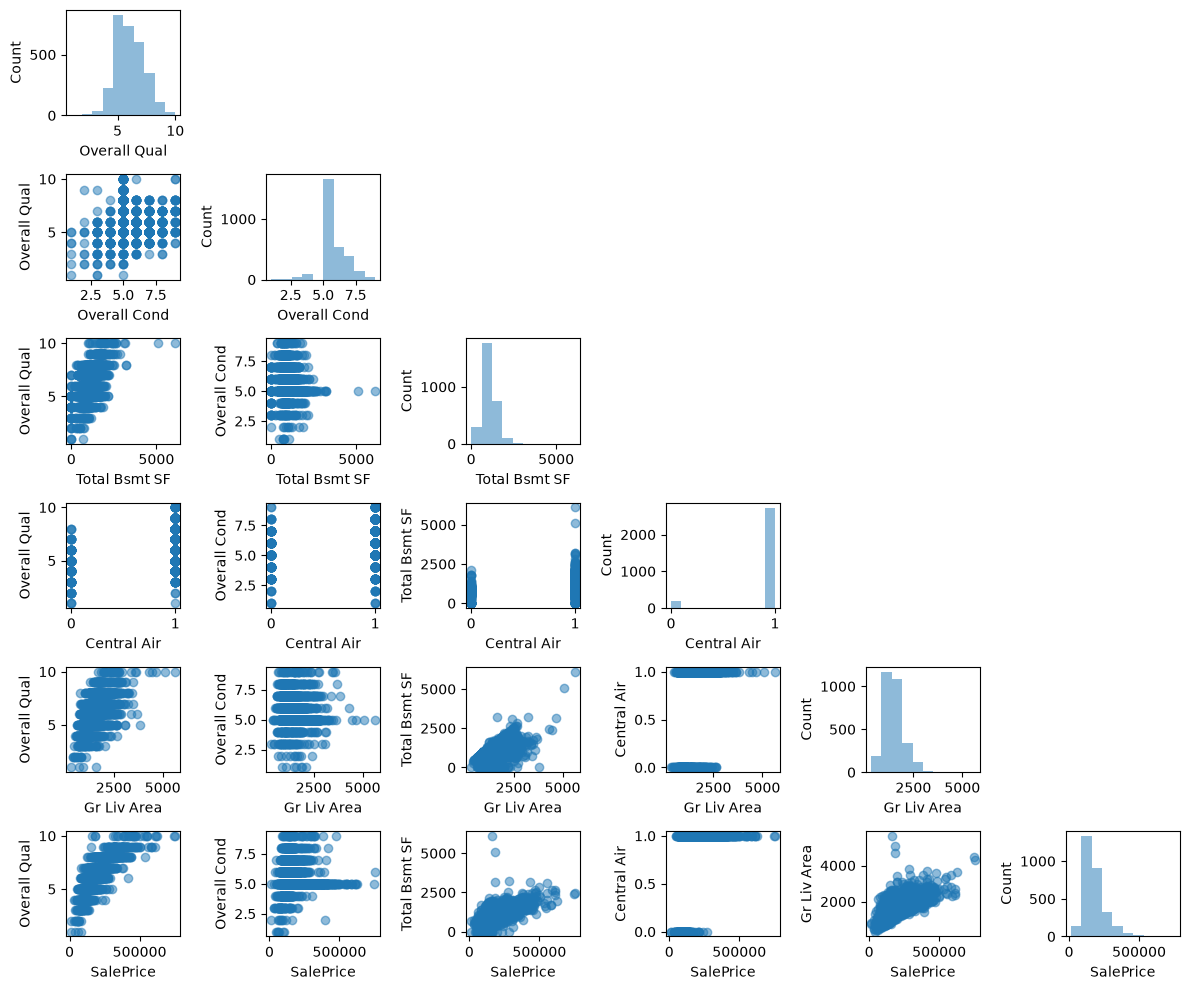

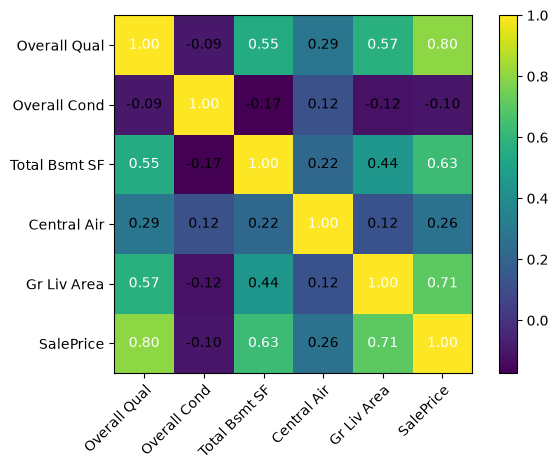

In [69]:
scatterplotmatrix(df.values, figsize=(12, 10), names=df.columns, alpha=0.5)
plt.tight_layout(); plt.show()

cm = np.corrcoef(df.values.T)
heatmap(cm, row_names=df.columns, column_names=df.columns)
plt.tight_layout(); plt.show()

---
## 4. Regresi Linear dengan Gradient Descent
Bagian ini membangun regresi linear dari nol. Karena Gradient Descent sensitif terhadap skala, satu fitur (`Gr Liv Area`) dan target `SalePrice` distandarisasi terlebih dahulu menggunakan `StandardScaler`.

### A. Standardisasi fitur dan target

In [70]:
X = df[['Gr Liv Area']].values
y = df['SalePrice'].values

sc_x = StandardScaler()
sc_y = StandardScaler()
X_std = sc_x.fit_transform(X)
y_std = sc_y.fit_transform(y[:, np.newaxis]).flatten()

### B. LinearRegressionGD

In [71]:
class LinearRegressionGD:
    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(0.0, 0.01, size=X.shape[1])
        self.b_ = np.array([0.])
        self.losses_ = []
        for _ in range(self.n_iter):
            output = self.net_input(X)
            errors = y - output
            self.w_ += self.eta * 2.0 * X.T.dot(errors) / X.shape[0]
            self.b_ += self.eta * 2.0 * errors.mean()
            self.losses_.append((errors**2).mean())
        return self

    def net_input(self, X):
        return np.dot(X, self.w_) + self.b_

    def predict(self, X):
        return self.net_input(X)

### C. Melatih model dan learning curve

MSE Awal : 0.9773
MSE Akhir: 0.5007


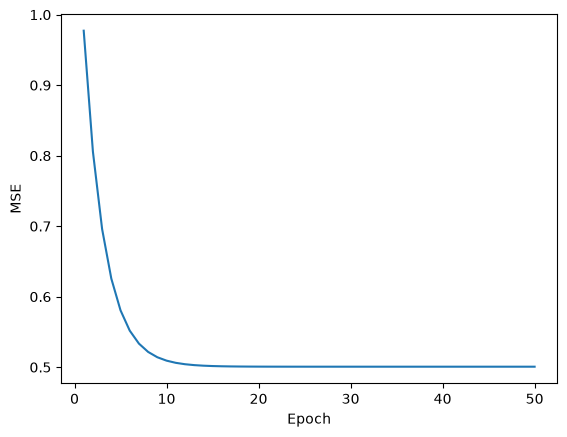

In [72]:
lr = LinearRegressionGD(eta=0.1)
lr.fit(X_std, y_std)
print(f'MSE Awal : {lr.losses_[0]:.4f}')
print(f'MSE Akhir: {lr.losses_[-1]:.4f}')

plt.plot(range(1, lr.n_iter + 1), lr.losses_)
plt.ylabel('MSE')
plt.xlabel('Epoch')
plt.show()

### D. Eksperimen LinearRegressionGD

| eta | n_iter | MSE awal | MSE akhir |
| :--- | :--- | :--- | :--- |
| 0.001 | 50 | 0.9773 | 0.8924 |
| 0.01 | 50 | 0.9773 | 0.5665 |
| 0.1 | 50 | 0.9773 | 0.5007 |
| 0.5 | 50 | 0.9773 | 0.5007 |

In [73]:
# Eksperimen variasi learning rate (eta)
for eta in [0.001, 0.01, 0.1, 0.5]:
    lr_exp = LinearRegressionGD(eta=eta, n_iter=50)
    lr_exp.fit(X_std, y_std)
    print(f"eta: {eta:<5} | MSE Awal: {lr_exp.losses_[0]:.4f} | MSE Akhir: {lr_exp.losses_[-1]:.4f}")

eta: 0.001 | MSE Awal: 0.9773 | MSE Akhir: 0.8924
eta: 0.01  | MSE Awal: 0.9773 | MSE Akhir: 0.5665
eta: 0.1   | MSE Awal: 0.9773 | MSE Akhir: 0.5007
eta: 0.5   | MSE Awal: 0.9773 | MSE Akhir: 0.5007


### E. Prediksi rumah 2500 sqft

In [74]:
feature_std = sc_x.transform(np.array([[2500]]))
target_std = lr.predict(feature_std)
target_reverted = sc_y.inverse_transform(target_std.reshape(-1, 1))
print(f'Sale price: ${target_reverted.flatten()[0]:.2f}')

Sale price: $292507.07


---
## 5. Linear Regression Scikit-Learn dan Normal Equation
Notebook kemudian kembali ke skala asli dan melatih `LinearRegression` pada `Gr Liv Area`. Hasilnya dibandingkan dengan solusi analitik Normal Equation.

### A. LinearRegression

In [75]:
X = df[['Gr Liv Area']].values
y = df['SalePrice'].values

slr = LinearRegression()
slr.fit(X, y)
print(f'Slope: {slr.coef_[0]:.3f}')
print(f'Intercept: {slr.intercept_:.3f}')

Slope: 111.666
Intercept: 13342.979


Slope = 111.666 dan intercept = 13,342.979. Dalam model satu fitur ini, slope dapat dibaca sebagai perubahan prediksi `SalePrice` untuk setiap tambahan 1 sqft `Gr Liv Area`.

### B. Normal Equation

In [76]:
Xb = np.hstack((np.ones((X.shape[0], 1)), X))
z = np.linalg.inv(Xb.T @ Xb)
w = z @ Xb.T @ y
print(f'Slope: {w[1]:.3f}')
print(f'Intercept: {w[0]:.3f}')

Slope: 111.666
Intercept: 13342.979


$w = (X^T X)^{-1} X^T y$. Pada notebook sumber, solusi ini menghasilkan slope dan intercept yang sama dengan `LinearRegression` untuk eksperimen satu fitur.

| Metode | Slope | Intercept | Iteratif? |
| :--- | :--- | :--- | :--- |
| **Gradient Descent (standardized)** | 0.707 | ≈ 0.000 | Ya |
| **LinearRegression sklearn** | 111.666 | 13,342.979 | Tidak terlihat oleh pengguna |
| **Normal Equation** | 111.666 | 13,342.979 | Tidak |

---
## 6. Robust Regression dengan RANSAC
RANSAC mencari model dari sampel data dan mengidentifikasi observasi sebagai inlier atau outlier berdasarkan residual. Notebook menjalankan RANSAC dua kali: threshold default, lalu `residual_threshold=65000`.

### A. RANSAC

In [77]:
ransac = RANSACRegressor(
    LinearRegression(), max_trials=100,
    min_samples=0.95, loss='absolute_error',
    residual_threshold=None, random_state=123
)
ransac.fit(X, y)

inlier_mask = ransac.inlier_mask_
outlier_mask = np.logical_not(inlier_mask)
print(f'Koefisien : {ransac.estimator_.coef_}')
print(f'Intercept : {ransac.estimator_.intercept_}')

Koefisien : [106.34799704]
Intercept : 20190.092616849026


RANSAC default: slope = 106.348, intercept = 20,190.093. Median absolute deviation (MAD) target $y$ yang dihitung notebook = 37,000.

### B. RANSAC dengan threshold 65,000

In [78]:
ransac = RANSACRegressor(
    LinearRegression(), max_trials=100,
    min_samples=0.95, loss='absolute_error',
    residual_threshold=65000, random_state=123
)
ransac.fit(X, y)

print('RANSAC threshold = 65000')
print(f'Koefisien : {ransac.estimator_.coef_}')
print(f'Intercept : {ransac.estimator_.intercept_}')

RANSAC threshold = 65000
Koefisien : [105.63090759]
Intercept : 18314.586835644557


Dengan `residual_threshold=65000`: slope = 105.631 dan intercept = 18,314.587.

### C. Perbaikan visualisasi RANSAC

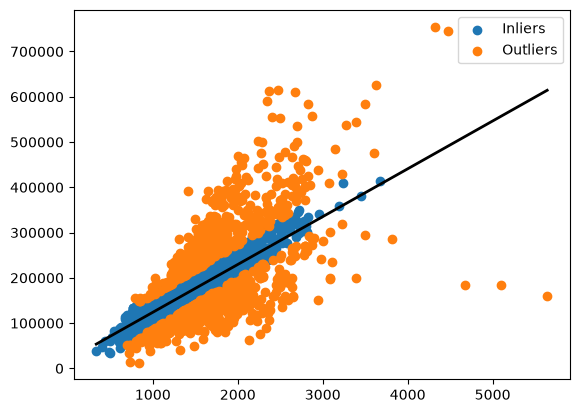

In [79]:
line_X = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
line_y_ransac = ransac.predict(line_X)

plt.scatter(X[inlier_mask], y[inlier_mask], label='Inliers')
plt.scatter(X[outlier_mask], y[outlier_mask], label='Outliers')
plt.plot(line_X, line_y_ransac, color='black', lw=2)
plt.legend(); plt.show()

---
## 7. Evaluasi Regresi Linear dengan Train-Test Split
Berbeda dengan eksperimen satu fitur sebelumnya, bagian ini memakai seluruh fitur selain `SalePrice`: `Overall Qual`, `Overall Cond`, `Gr Liv Area`, `Central Air`, dan `Total Bsmt SF`. Split 70:30 menggunakan `random_state=123`.

In [80]:
target = 'SalePrice'
features = df.columns[df.columns != target]
X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)
slr = LinearRegression().fit(X_train, y_train)
y_train_pred = slr.predict(X_train)
y_test_pred = slr.predict(X_test)

print('Training:')
print(f'MSE: {mean_squared_error(y_train, y_train_pred):.2f}')
print(f'MAE: {mean_absolute_error(y_train, y_train_pred):.2f}')
print(f'R2 : {r2_score(y_train, y_train_pred):.4f}')

print('\nTesting:')
print(f'MSE: {mean_squared_error(y_test, y_test_pred):.2f}')
print(f'MAE: {mean_absolute_error(y_test, y_test_pred):.2f}')
print(f'R2 : {r2_score(y_test, y_test_pred):.4f}')

Training:
MSE: 1497216245.85
MAE: 25983.03
R2 : 0.7695

Testing:
MSE: 1516565821.00
MAE: 24921.29
R2 : 0.7516


| Metrik | Train | Test |
| :--- | :--- | :--- |
| **MSE** | 1,497,216,245.85 | 1,516,565,821.00 |
| **MAE** | $25,983.03 | $24,921.29 |
| **R²** | 0.77 | 0.75 |

---
## 8. Regularisasi: Lasso, Ridge, dan ElasticNet
Notebook menjelaskan tiga teknik regularisasi, tetapi eksperimen yang benar-benar di-fit dan dievaluasi hanya Lasso. Ridge dan ElasticNet baru diinisialisasi. Pada Practice Lab, bagian ini harus dilengkapi agar perbandingan sesuai dengan tujuan modul.

### A. Lasso

In [81]:
lasso = Lasso(alpha=1.0)
lasso.fit(X_train, y_train)
y_train_pred = lasso.predict(X_train)
y_test_pred = lasso.predict(X_test)
print(lasso.coef_)

[26251.38276394   804.70816337    41.94651964 11364.80761309
    55.67855548]


Koefisien Lasso alpha=1.0: `[26251.38, 804.71, 41.95, 11364.81, 55.68]`. Tidak ada koefisien yang menjadi 0 pada konfigurasi ini. R² train ≈ 0.769 dan test ≈ 0.752.

### B. Kerangka perbandingan regularisasi

In [82]:
models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0),
    'ElasticNet': ElasticNet(alpha=1.0, l1_ratio=0.5)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    tr = model.predict(X_train)
    te = model.predict(X_test)
    print(name,
          f'MAE test = {mean_absolute_error(y_test, te):.3f}',
          f'R2 test = {r2_score(y_test, te):.3f}')

Ridge MAE test = 24921.208 R2 test = 0.752
Lasso MAE test = 24921.395 R2 test = 0.752
ElasticNet MAE test = 25274.256 R2 test = 0.727


| Model | MAE Test | R² Test |
| :--- | :--- | :--- |
| **Ridge** | 24,921.208 | 0.752 |
| **Lasso** | 24,921.395 | 0.752 |
| **ElasticNet** | 25,274.256 | 0.727 |

---
## 9. Linear vs Polynomial Regression pada Dataset Kecil
Notebook memakai 10 titik data sintetis untuk memperlihatkan bagaimana `PolynomialFeatures degree=2` dapat menangkap pola melengkung yang tidak tertangkap garis lurus.

### A. 10 data sintetis

In [83]:
X = np.array([258.0, 270.0, 294.0,
              320.0, 342.0, 368.0,
              396.0, 446.0, 480.0, 586.0])\
             [:, np.newaxis]

y = np.array([236.4, 234.4, 252.8,
              298.6, 314.2, 342.2,
              360.8, 368.0, 391.2,
              390.8])

### B. PolynomialFeatures degree=2

In [84]:
quadratic = PolynomialFeatures(degree=2)
X_quad = quadratic.fit_transform(X)

lr = LinearRegression().fit(X, y)
pr = LinearRegression().fit(X_quad, y)

y_lin_pred = lr.predict(X)
y_quad_pred = pr.predict(X_quad)

print('Linear Regression')
print(f'Training MSE: {mean_squared_error(y, y_lin_pred):.3f}')
print(f'Training R2 : {r2_score(y, y_lin_pred):.3f}')

print('\nQuadratic Regression')
print(f'Training MSE: {mean_squared_error(y, y_quad_pred):.3f}')
print(f'Training R2 : {r2_score(y, y_quad_pred):.3f}')

Linear Regression
Training MSE: 569.780
Training R2 : 0.832

Quadratic Regression
Training MSE: 61.330
Training R2 : 0.982


| Model | Training MSE | Training R² |
| :--- | :--- | :--- |
| **Linear** | 569.780 | 0.832 |
| **Quadratic** | 61.330 | 0.982 |

---
## 10. Linear, Quadratic, dan Cubic pada Ames Housing
Notebook mengulang eksperimen polynomial pada dua fitur: `Gr Liv Area` dan `Overall Qual`. Untuk `Gr Liv Area`, rumah dengan luas di atas 4000 sqft dikeluarkan sebelum kurva linear/quadratic/cubic dilatih. Untuk `Overall Qual`, semua data digunakan.

### A. Data luas diatas 4000 sqft

In [85]:
X = df[['Gr Liv Area']].values
y = df['SalePrice'].values

X = X[(df['Gr Liv Area'] < 4000)]
y = y[(df['Gr Liv Area'] < 4000)]

regr = LinearRegression()

### B. Kerangka polynomial degree 1–3

In [86]:
quadratic = PolynomialFeatures(degree=2)
cubic = PolynomialFeatures(degree=3)

X_quad = quadratic.fit_transform(X)
X_cubic = cubic.fit_transform(X)

lin_model = LinearRegression().fit(X, y)
quad_model = LinearRegression().fit(X_quad, y)
cubic_model = LinearRegression().fit(X_cubic, y)

print('R2 linear:', r2_score(y, lin_model.predict(X)))
print('R2 quadratic:', r2_score(y, quad_model.predict(X_quad)))
print('R2 cubic:', r2_score(y, cubic_model.predict(X_cubic)))

R2 linear: 0.5174078398002504
R2 quadratic: 0.5176057493005759
R2 cubic: 0.5168438435725369


### C. Eksperimen Gr Liv Area vs Overall Qual

| Fitur | R² Linear | R² Quadratic | R² Cubic |
| :--- | :--- | :--- | :--- |
| **Gr Liv Area** | 0.5174 | 0.5176 | 0.5168 |
| **Overall Qual** | 0.6386 | 0.6928 | 0.6997 |

In [87]:
# Eksperimen polynomial untuk Overall Qual
X_oq = df[['Overall Qual']].values
y_oq = df['SalePrice'].values

X_oq_quad = quadratic.fit_transform(X_oq)
X_oq_cubic = cubic.fit_transform(X_oq)

lin_oq = LinearRegression().fit(X_oq, y_oq)
quad_oq = LinearRegression().fit(X_oq_quad, y_oq)
cubic_oq = LinearRegression().fit(X_oq_cubic, y_oq)

print('Overall Qual - R2 linear:', r2_score(y_oq, lin_oq.predict(X_oq)))
print('Overall Qual - R2 quadratic:', r2_score(y_oq, quad_oq.predict(X_oq_quad)))
print('Overall Qual - R2 cubic:', r2_score(y_oq, cubic_oq.predict(X_oq_cubic)))

Overall Qual - R2 linear: 0.6386216382995367
Overall Qual - R2 quadratic: 0.6927823564507078
Overall Qual - R2 cubic: 0.6997332379865048


---
## 11. Decision Tree Regression
DecisionTreeRegressor digunakan pada satu fitur `Gr Liv Area` dengan `max_depth=3`. Prediksi pohon berbentuk step function karena ruang fitur dibagi menjadi interval berdasarkan aturan split.

### A. Decision Tree Regressor

In [88]:
X = df[['Gr Liv Area']].values
y = df['SalePrice'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)

tree = DecisionTreeRegressor(max_depth=3)
tree.fit(X_train, y_train)

y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

print(f'Training R2: {r2_score(y_train, y_train_pred):.4f}')
print(f'Testing R2 : {r2_score(y_test, y_test_pred):.4f}')

Training R2: 0.5179
Testing R2 : 0.4796


### B. Eksperimen Decision Tree Regressor

| max_depth | Training R² | Test R² |
| :--- | :--- | :--- |
| 1 | 0.3236 | 0.3185 |
| 5 | 0.5699 | 0.4408 |
| 10 | 0.7042 | 0.3021 |
| 15 | 0.7926 | 0.1773 |

In [89]:
# Eksperimen Decision Tree Regressor dengan variasi max_depth
for depth in [1, 5, 10, 15]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=123)
    dt.fit(X_train, y_train)
    tr_r2 = r2_score(y_train, dt.predict(X_train))
    te_r2 = r2_score(y_test, dt.predict(X_test))
    print(f"max_depth: {depth:<2} | Training R2: {tr_r2:.4f} | Testing R2: {te_r2:.4f}")

max_depth: 1  | Training R2: 0.3236 | Testing R2: 0.3185
max_depth: 5  | Training R2: 0.5699 | Testing R2: 0.4408
max_depth: 10 | Training R2: 0.7042 | Testing R2: 0.3021
max_depth: 15 | Training R2: 0.7926 | Testing R2: 0.1773


---
## 12. Random Forest Regression
Random Forest pada notebook menggunakan semua lima fitur prediktor, split 70:30 dengan `random_state=123`, 1000 trees, dan squared_error. Ini memungkinkan perbandingan yang lebih fair dengan regresi linear multivariat pada Bagian 6 karena fitur dan split-nya sama.

### A. Random Forest Regressor

In [90]:
target = 'SalePrice'
features = df.columns[df.columns != target]

X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123)

forest = RandomForestRegressor(n_estimators=1000,
                               criterion='squared_error',
                               random_state=1,
                               n_jobs=-1)

### B. Latih Model Random Forest

In [91]:
forest.fit(X_train, y_train)
y_train_pred = forest.predict(X_train)
y_test_pred = forest.predict(X_test)

mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)
print(f'MAE train: {mae_train:.2f}')
print(f'MAE test: {mae_test:.2f}')

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
print(f'R^2 train: {r2_train:.2f}')
print(f'R^2 test: {r2_test:.2f}')

MAE train: 8305.18
MAE test: 20821.77
R^2 train: 0.98
R^2 test: 0.85


| Metrik | Train | Test |
| :--- | :--- | :--- |
| **MAE** | 8,305.18 | 20,821.77 |
| **R²** | 0.98 | 0.85 |

### C. Eksperimen Random Forest Regression

| n_estimators | MAE Test | R² Test | Waktu Fit (s) |
| :--- | :--- | :--- | :--- |
| 50 | 20,945.26 | 0.8453 | 0.23 |
| 100 | 20,793.73 | 0.8478 | 0.18 |
| 300 | 20,772.59 | 0.8476 | 0.44 |
| 500 | 20,836.28 | 0.8471 | 0.69 |

In [92]:
import time

# Eksperimen variasi n_estimators Random Forest Regression
for n_est in [50, 100, 300, 500]:
    rf_exp = RandomForestRegressor(n_estimators=n_est, criterion='squared_error', random_state=1, n_jobs=-1)
    start_time = time.time()
    rf_exp.fit(X_train, y_train)
    fit_time = time.time() - start_time
    te_pred = rf_exp.predict(X_test)
    print(f"n_estimators: {n_est:<3} | MAE Test: {mean_absolute_error(y_test, te_pred):.2f} | R2 Test: {r2_score(y_test, te_pred):.4f} | Waktu Fit: {fit_time:.2f}s")

n_estimators: 50  | MAE Test: 20945.26 | R2 Test: 0.8453 | Waktu Fit: 0.09s
n_estimators: 100 | MAE Test: 20793.73 | R2 Test: 0.8478 | Waktu Fit: 0.18s
n_estimators: 300 | MAE Test: 20772.59 | R2 Test: 0.8476 | Waktu Fit: 0.45s
n_estimators: 500 | MAE Test: 20836.28 | R2 Test: 0.8471 | Waktu Fit: 0.70s


---
## 13. Model Persistence dan Reproducibility
Notebook menyimpan tiga model yaitu Logistic Regression, Decision Tree Regressor, dan Random Forest Regressor ke dalam bentuk pkl dan di simpan folder Stremlit.

### A. Menentukan Model

In [93]:
from pathlib import Path

folder = Path("Streamlit")
folder.mkdir(parents=True, exist_ok=True)

# Menentukan model
models = {
    "Linear_Regression": LinearRegression(),
    "Decision_Tree": DecisionTreeRegressor(
        max_depth=5, random_state=123
    ),
    "Random_Forest": RandomForestRegressor(
        n_estimators=100, random_state=123, n_jobs=-1
    )
}

### B. Melatih dan meyimpan model

In [94]:
import pickle

# Menyiapkan 1 fitur (Gr Liv Area) sesuai spesifikasi deployment Streamlit
X_single = df[["Gr Liv Area"]].values
y_single = df["SalePrice"].values
X_train_single, X_test_single, y_train_single, y_test_single = train_test_split(
    X_single, y_single, test_size=0.3, random_state=123
)

for nama, model in models.items():
    model.fit(X_train_single, y_train_single)

    lokasi = folder / f"{nama}.pkl"

    with open(lokasi, "wb") as file:
        pickle.dump(model, file)

    print(f"{nama} berhasil disimpan (1 fitur: Gr Liv Area)")
    print(f"Lokasi: {lokasi.resolve()}\n")

Linear_Regression berhasil disimpan (1 fitur: Gr Liv Area)
Lokasi: /home/neuxbane/Downloads/Modul 5/Streamlit/Linear_Regression.pkl

Decision_Tree berhasil disimpan (1 fitur: Gr Liv Area)
Lokasi: /home/neuxbane/Downloads/Modul 5/Streamlit/Decision_Tree.pkl

Random_Forest berhasil disimpan (1 fitur: Gr Liv Area)
Lokasi: /home/neuxbane/Downloads/Modul 5/Streamlit/Random_Forest.pkl



---
## Mini Project – Prediksi Harga Rumah menggunakan 3 Model Regresi
### Spesifikasi Mini Project
Mini project ini menggunakan dataset Ames Housing untuk memprediksi harga rumah berdasarkan luas bangunan (`Gr Liv Area`) menggunakan tiga model, yaitu Linear Regression, Decision Tree Regression, dan Random Forest Regression.

| Luas Rumah | Linier Regression | Decision Tree Regression | Random Forest Regression |
| :--- | :--- | :--- | :--- |
| **10000** | $1,130,006.18 | $370,284.86 | $188,234.85 |
| **20000** | $2,246,668.04 | $370,284.86 | $188,234.85 |
| **30000** | $3,363,330.64 | $370,284.86 | $188,234.85 |
| **40000** | $4,479,992.51 | $370,284.86 | $188,234.85 |

In [95]:
# Mini Project - Prediksi Harga Rumah dengan 3 Model Regresi berdasarkan 'Gr Liv Area'
X_single = df[['Gr Liv Area']].values
y_single = df['SalePrice'].values

lr_single = LinearRegression().fit(X_single, y_single)
dt_single = DecisionTreeRegressor(max_depth=3, random_state=123).fit(X_single, y_single)
rf_single = RandomForestRegressor(n_estimators=1000, random_state=1, n_jobs=-1).fit(X_single, y_single)

test_areas = np.array([[10000], [20000], [30000], [40000]])

pred_lr = lr_single.predict(test_areas)
pred_dt = dt_single.predict(test_areas)
pred_rf = rf_single.predict(test_areas)

comparison_df = pd.DataFrame({
    'Luas Rumah': test_areas.flatten(),
    'Linier Regression': pred_lr,
    'Decision Tree Regression': pred_dt,
    'Random Forest Regression': pred_rf
})
comparison_df

,Luas Rumah,Linier Regression,Decision Tree Regression,Random Forest Regression
0,10000,1.130006e+06,370284.855263,188234.85
1,20000,2.246668e+06,370284.855263,188234.85
2,30000,3.363331e+06,370284.855263,188234.85
3,40000,4.479993e+06,370284.855263,188234.85


---
## Rubrik Penilaian

| Komponen | Bobot | Indikator |
| :--- | :--- | :--- |
| **Reproducibility** | 10% | Kode dapat dijalankan ulang tanpa error, penggunaan `random_state`, konsistensi preprocessing, serta keberhasilan save-load model dan metadata. |
| **Regresi** | 20% | Data preparation & EDA, implementasi Gradient Descent, Linear Regression, Normal Equation, RANSAC, regularisasi, Polynomial Regression, Decision Tree, Random Forest, serta evaluasi MSE, MAE, dan R². |
| **Eksperimen** | 20% | Eksperimen learning rate (`eta`), regularisasi dan scaling, polynomial degree, `max_depth`, `n_estimators`, analisis train-test gap, serta perbandingan performa model secara adil. |
| **Mini Project** | 20% | Implementasi prediksi harga rumah menggunakan Linear Regression, Decision Tree, dan Random Forest pada luas rumah yang ditentukan, penyajian tabel hasil prediksi, serta analisis perbandingan ketiga model. |
| **Checkpoint** | 20% | Kelengkapan dan ketepatan jawaban checkpoint pada worksheet, interpretasi hasil eksperimen, pemahaman konsep regresi, serta kesimpulan berdasarkan hasil pengujian. |
| **Kerapihan** | 10% | Struktur notebook sistematis, penamaan variabel jelas, kode mudah dibaca, visualisasi informatif, output tertata, serta dokumentasi hasil yang rapi. |